# Simple plasma lens from file example

Loads the Bx and By maps explicitly with `load()`, then tracks a beam through `PlasmaLensFromFile`.


In [1]:
import numpy as np
from abel import *
%load_ext autoreload
%autoreload 2


Could not import HiPACE++ tools from /Users/nikitavg/code/hipace/tools


## Define the beamline and lens

In [2]:
# define beam
source = SourceBasic()
source.charge = -100e-12
source.energy = 50e6
source.rel_energy_spread = 0.01
source.bunch_length = 400e-6
source.emit_nx = source.emit_ny = 5e-6
source.beta_x = source.beta_y = 10
source.num_particles = 10000
source.length = 3
source.jitter.x = source.jitter.y = 100e-6
source.jitter.xp = source.jitter.yp = 0.01e-3

# define the RF accelerator
rf_accelerator = RFAcceleratorBasic()
rf_accelerator.nom_energy_gain = 200e6
rf_accelerator.length = 200

# define the BDS
bds = BeamDeliverySystemBasic()
bds.beta_x = bds.beta_y = 0.2
bds.length = 5

# define linac
linac = ConventionalLinac()
linac.source = source
linac.rf_accelerator = rf_accelerator
linac.bds = bds

# define the plasma lens
plasma_lens = PlasmaLensFromFile()
plasma_lens.length = 0.02 # [m]
plasma_lens.discharge_time = 195e-9 #[s]
plasma_lens.num_slice = 30
plasma_lens.external_magnetic_field_y = 300e-3 #[T]
plasma_lens.imported_magnetic_field_polarity = -1 
BX_FILE =  "input_files/Bx.txt"
BY_FILE =  "input_files/By.txt"
plasma_lens.load(
    filename_Bx=BX_FILE,
    filename_By=BY_FILE,
    time_scale=1e-9
)

# define the spectrometer
spectrometer = SpectrometerBasicCLEAR()
spectrometer.use_otr_screen = True

# assemble 
experiment = ExperimentAPL()
experiment.linac = linac
experiment.plasma_lens = plasma_lens
experiment.spectrometer = spectrometer

## Plot the imported and total field maps

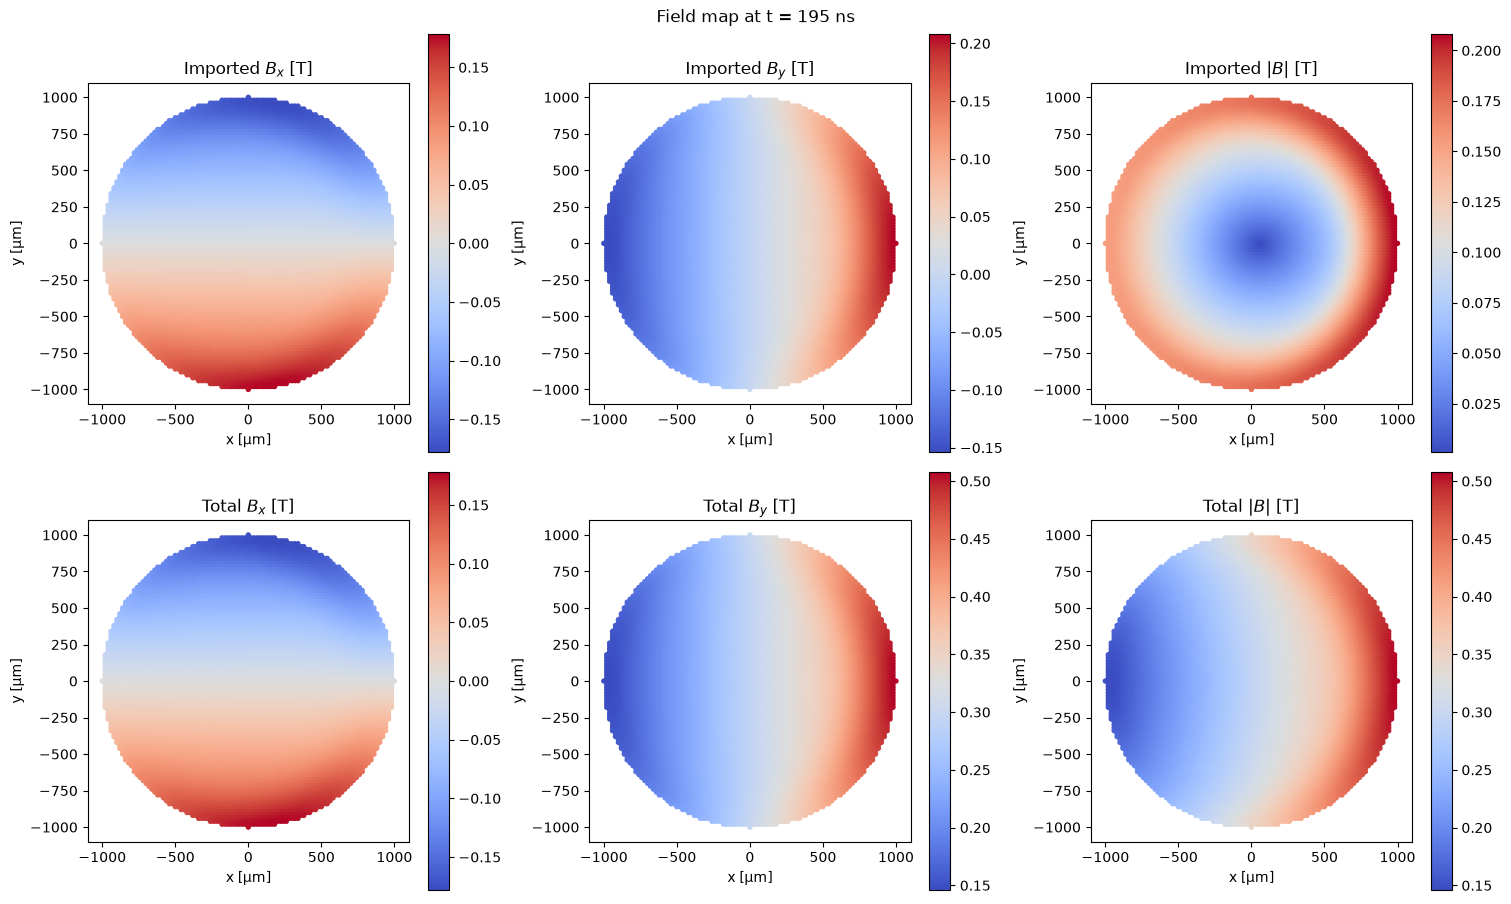

(<Figure size 1500x900 with 12 Axes>,
 array([[<Axes: title={'center': 'Imported $B_x$ [T]'}, xlabel='x [µm]', ylabel='y [µm]'>,
         <Axes: title={'center': 'Imported $B_y$ [T]'}, xlabel='x [µm]', ylabel='y [µm]'>,
         <Axes: title={'center': 'Imported $|B|$ [T]'}, xlabel='x [µm]', ylabel='y [µm]'>],
        [<Axes: title={'center': 'Total $B_x$ [T]'}, xlabel='x [µm]', ylabel='y [µm]'>,
         <Axes: title={'center': 'Total $B_y$ [T]'}, xlabel='x [µm]', ylabel='y [µm]'>,
         <Axes: title={'center': 'Total $|B|$ [T]'}, xlabel='x [µm]', ylabel='y [µm]'>]],
       dtype=object))

In [3]:
plasma_lens.plot_field_map()

## Run and scan the vertical lens offset

In [4]:
experiment.run('plasmalens_fromfile_edited_simple_run',
              num_shots=1, parallel=False, overwrite=True)

Tracked #0  SourceBasic                 (s =    3.0 m) :   E =   0.0 GeV, Q = -0.10 nC, σz = 399.8 µm, σE =  1.0%, ε =   5.0/4.98 mm-mrad
    ... #1  RFAcceleratorBasic          (s =  203.0 m) :   E =   0.2 GeV, Q = -0.10 nC, σz = 399.8 µm, σE =  0.2%, ε =   5.0/4.98 mm-mrad
    ... #2  BeamDeliverySystemBasic     (s =  208.0 m) :   E =   0.2 GeV, Q = -0.10 nC, σz = 399.8 µm, σE =  0.2%, ε =   5.0/4.98 mm-mrad
    ... #3  PlasmaLensFromFile          (s =  208.0 m) :   E =   0.2 GeV, Q = -0.10 nC, σz = 399.8 µm, σE =  0.2%, ε =   5.0/4.98 mm-mrad
    ... #4  SpectrometerBasicCLEAR      (s =  208.3 m) :   E =   0.2 GeV, Q = -0.10 nC, σz = 399.8 µm, σE =  0.2%, ε =   5.0/4.98 mm-mrad


In [18]:
# scan the plasma lens vertical offset

experiment.scan(
    'plasmalens_fromfile_edited_simple_offset_scan',
    lambda obj, val: (setattr(obj.plasma_lens, 'offset_x', 0.0)
                      or setattr(obj.plasma_lens, 'offset_y', val) or obj),
    np.linspace(-plasma_lens.get_map_radius(), plasma_lens.get_map_radius(), 11),
    label='Plasma lens vertical offset (um)', scale=1e-6,
    num_shots_per_step=1, parallel=False, overwrite=True,
)

>> SHOT 1/11
Tracked #0  SourceBasic                 (s =    3.0 m) :   E =   0.1 GeV, Q = -0.10 nC, σz = 401.6 µm, σE =  1.0%, ε =   4.9/5.05 mm-mrad
    ... #1  RFAcceleratorBasic          (s =  203.0 m) :   E =   0.3 GeV, Q = -0.10 nC, σz = 401.6 µm, σE =  0.2%, ε =   4.9/5.05 mm-mrad
    ... #2  BeamDeliverySystemBasic     (s =  208.0 m) :   E =   0.3 GeV, Q = -0.10 nC, σz = 401.6 µm, σE =  0.2%, ε =   4.9/5.05 mm-mrad
    ... #3  PlasmaLensFromFile          (s =  208.0 m) :   E =   0.3 GeV, Q = -0.04 nC, σz = 400.5 µm, σE =  0.2%, ε =   4.8/4.98 mm-mrad
    ... #4  SpectrometerBasicCLEAR      (s =  208.3 m) :   E =   0.3 GeV, Q = -0.04 nC, σz = 400.5 µm, σE =  0.2%, ε =   4.8/5.00 mm-mrad
>> SHOT 2/11
Tracked #0  SourceBasic                 (s =    3.0 m) :   E =   0.0 GeV, Q = -0.10 nC, σz = 403.1 µm, σE =  1.0%, ε =   5.0/4.99 mm-mrad
    ... #1  RFAcceleratorBasic          (s =  203.0 m) :   E =   0.2 GeV, Q = -0.10 nC, σz = 403.1 µm, σE =  0.2%, ε =   5.0/4.99 mm-mrad
    ... 

/Users/nikitavg/Oslo_sims/Bfieldimplementation/ABEL/src/abel/classes/runnable.py:518: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


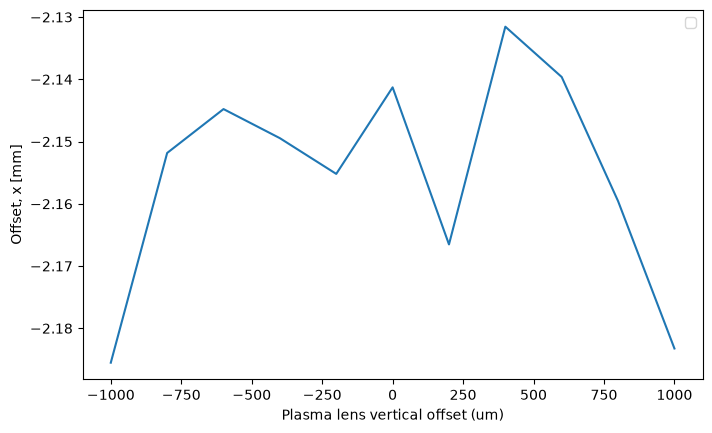

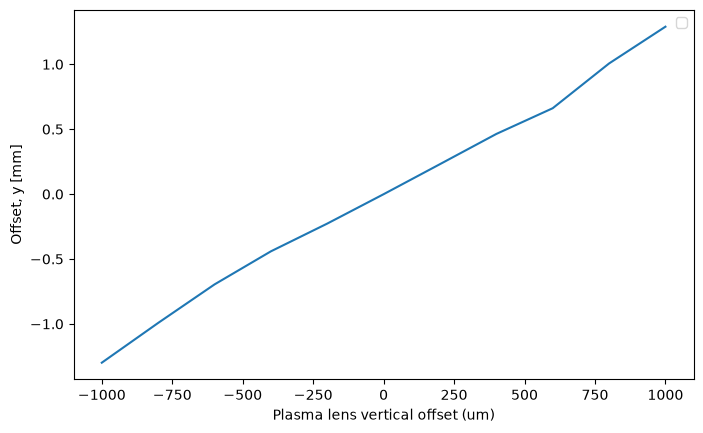

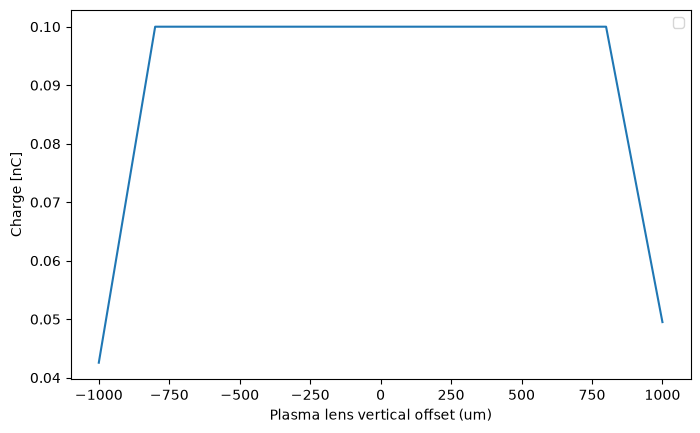

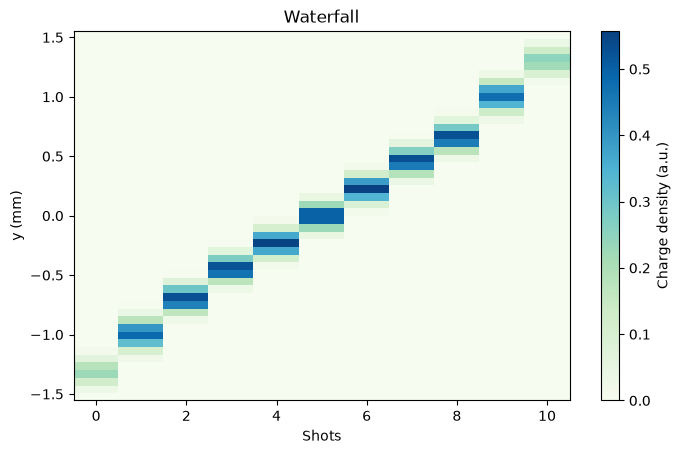

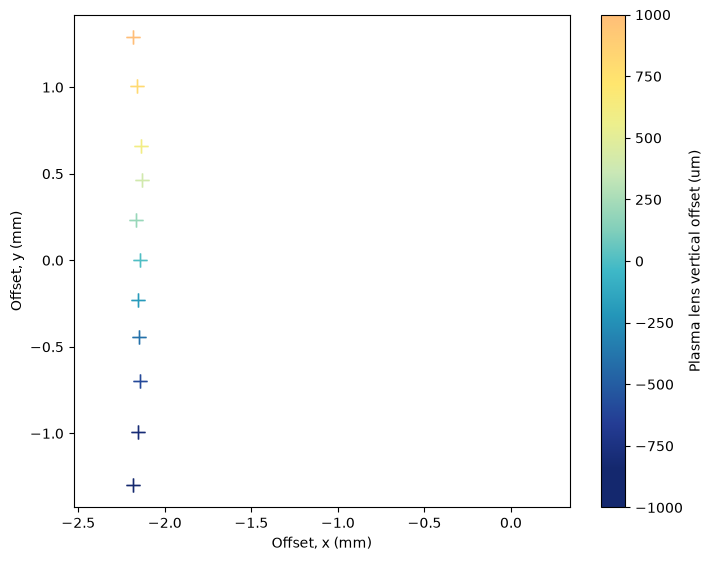

In [19]:
# show outputs
experiment.plot_beam_function(Beam.x_offset, label='Offset, x [mm]', scale=1e-3)
experiment.plot_offset_y()
experiment.plot_charge()
experiment.plot_waterfall_y()
experiment.plot_correlation_offsets()